# Level 2 — Task 2: Price Range Analysis

**Cognifyz Technologies — Data Science Internship**

## Introduction
Every restaurant in the dataset is assigned a `Price range` category. This notebook studies how restaurants are spread across those categories, how their ratings differ, and which **rating colour** is associated with the highest ratings.

## Objectives
1. Inspect the `Price range` column (values, data type, missing values).
2. Find the most common price range with its restaurant count and percentage.
3. Calculate the average rating for every price range, together with the median, count and variability.
4. Identify the price range with the highest average rating from the computed results.
5. Identify the rating colour associated with the highest average rating, and explain ties or limitations instead of guessing.
6. Visualise restaurant counts, average ratings and the rating-colour mix across price ranges.

## 1. Imports and Notebook Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# Consistent styling for every chart in this notebook
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 100,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)


def show_table(table, title):
    """Display a DataFrame with a bold title above it."""
    display(Markdown(f"**{title}**"))
    display(table)


def show_findings(findings):
    """Render a list of strings as a Markdown bullet list."""
    display(Markdown("\n".join(f"- {item}" for item in findings)))

## 2. Load the Dataset
The dataset is read from `../dataset/Dataset.csv` (run this notebook from the `Level2` folder). The cell stops with a clear message if the file or a required column is missing.

In [2]:
DATA_PATH = Path("../dataset/Dataset.csv")   # notebook is run from the Level2 folder
REQUIRED_COLUMNS = ["Price range", "Aggregate rating", "Rating color"]

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH}' (looked in: {DATA_PATH.resolve()}). "
        "Run this notebook from the 'Level2' folder and make sure 'Dataset/Dataset.csv' exists."
    )

try:
    df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding="latin-1")

df.columns = df.columns.str.strip()

missing_columns = [col for col in REQUIRED_COLUMNS if col not in df.columns]
if missing_columns:
    raise KeyError(f"Required column(s) missing from the dataset: {missing_columns}")

print(f"Loaded '{DATA_PATH}' successfully: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

Loaded '..\dataset\Dataset.csv' successfully: 9,551 rows x 21 columns


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.03,14.57,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.80,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.01,14.55,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.50,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.06,14.58,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.40,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.06,14.59,"Japanese, Sushi",1500,Botswana Pula(P),No,No,No,No,4,4.90,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.06,14.58,"Japanese, Korean",1500,Botswana Pula(P),Yes,No,No,No,4,4.80,Dark Green,Excellent,229


## 3. Inspect the Price Range Column
We check the data type, missing values and the distinct categories. `Price range` is an ordered category: a larger number means a higher price category.

In [3]:
price_info = pd.DataFrame({
    "Value": [
        str(df["Price range"].dtype),
        f"{int(df['Price range'].isna().sum()):,}",
        f"{df['Price range'].nunique(dropna=True)}",
        str(sorted(df["Price range"].dropna().unique().tolist())),
    ]
}, index=["Data type", "Missing values", "Distinct values", "Distinct categories"])
price_info.index.name = "Property"
show_table(price_info, "Price range column inspection")

raw_counts = df["Price range"].value_counts(dropna=False).sort_index().rename("Restaurants").to_frame()
raw_counts.index.name = "Price range"
show_table(raw_counts, "Raw value counts for Price range (missing values included)")

**Price range column inspection**

,Value
Property,
Data type,int64
Missing values,0
Distinct values,4
Distinct categories,"[1, 2, 3, 4]"


**Raw value counts for Price range (missing values included)**

,Restaurants
Price range,
1,4444
2,3113
3,1408
4,586


## 4. Data Preparation
* `Price range` and `Aggregate rating` are converted to numbers (invalid entries become missing instead of raising errors).
* Rows without a price range cannot be assigned to a category, so they are left out of the price-range tables; the number left out is printed.
* A rating of `0` means the restaurant has **not been rated** in this dataset (`Rating text` is "Not rated" and `Rating color` is "White"). Treating these zeros as real ratings would drag averages down, so rating statistics use **rated restaurants only** (rating > 0). The unrated counts are shown alongside so nothing is hidden.

In [4]:
df["Price range"] = pd.to_numeric(df["Price range"], errors="coerce")
df["Aggregate rating"] = pd.to_numeric(df["Aggregate rating"], errors="coerce")
df["Rating color"] = df["Rating color"].astype("string").str.strip()

df["Is Rated"] = df["Aggregate rating"].gt(0)

priced = df.dropna(subset=["Price range"]).copy()
priced["Price range"] = priced["Price range"].astype(int)
rated = priced[priced["Is Rated"]].copy()

print(f"Total restaurants:                          {len(df):,}")
print(f"Excluded (missing Price range):             {len(df) - len(priced):,}")
print(f"Restaurants with a price range:             {len(priced):,}")
print(f"  of which rated (rating > 0):              {len(rated):,}")
print(f"  of which unrated (rating 0 or missing):   {len(priced) - len(rated):,}")

Total restaurants:                          9,551
Excluded (missing Price range):             0
Restaurants with a price range:             9,551
  of which rated (rating > 0):              7,403
  of which unrated (rating 0 or missing):   2,148


## 5. Most Common Price Range
The price range with the largest number of restaurants is found with `value_counts`. Ties are checked explicitly.

In [5]:
price_counts = priced["Price range"].value_counts().sort_index()
price_share = price_counts / price_counts.sum() * 100

count_table = pd.DataFrame({"Restaurants": price_counts, "Share of restaurants (%)": price_share})
count_table.index.name = "Price range"
show_table(count_table, "Number and percentage of restaurants in each price range")

max_count = price_counts.max()
most_common_ranges = price_counts[price_counts == max_count].index.tolist()

if len(most_common_ranges) == 1:
    most_common = most_common_ranges[0]
    print(f"Most common price range: {most_common} "
          f"({price_counts[most_common]:,} restaurants, {price_share[most_common]:.2f}% of restaurants with a price range)")
else:
    most_common = most_common_ranges[0]
    print(f"Tie for most common price range: {most_common_ranges} with {max_count:,} restaurants each")

**Number and percentage of restaurants in each price range**

,Restaurants,Share of restaurants (%)
Price range,,
1,4444,46.53
2,3113,32.59
3,1408,14.74
4,586,6.14


Most common price range: 1 (4,444 restaurants, 46.53% of restaurants with a price range)


## 6. Rating Statistics by Price Range
For each price range we compute the number of rated restaurants, the **mean**, **median**, **standard deviation**, minimum and maximum of `Aggregate rating`. For context, the table also shows how many restaurants are unrated and what the mean would be if unrated zeros were wrongly included.

In [6]:
rating_stats = (
    rated.groupby("Price range")["Aggregate rating"]
    .agg(Rated_Restaurants="count", Mean_Rating="mean", Median_Rating="median",
         Std_Dev="std", Min_Rating="min", Max_Rating="max")
)

all_stats = priced.groupby("Price range")["Aggregate rating"].agg(All_Restaurants="size", Mean_Incl_Unrated="mean")

summary = rating_stats.join(all_stats, how="outer")
summary["Unrated Restaurants"] = (summary["All_Restaurants"] - summary["Rated_Restaurants"].fillna(0)).astype(int)
summary["Unrated (%)"] = summary["Unrated Restaurants"] / summary["All_Restaurants"] * 100
summary["Share of Restaurants (%)"] = summary["All_Restaurants"] / summary["All_Restaurants"].sum() * 100

summary = summary.rename(columns={
    "All_Restaurants": "Total Restaurants", "Rated_Restaurants": "Rated Restaurants",
    "Mean_Rating": "Mean Rating", "Median_Rating": "Median Rating", "Std_Dev": "Std. Deviation",
    "Min_Rating": "Min Rating", "Max_Rating": "Max Rating",
    "Mean_Incl_Unrated": "Mean incl. unrated zeros",
})[["Total Restaurants", "Share of Restaurants (%)", "Rated Restaurants", "Unrated Restaurants", "Unrated (%)",
    "Mean Rating", "Median Rating", "Std. Deviation", "Min Rating", "Max Rating", "Mean incl. unrated zeros"]]
summary.index.name = "Price range"
show_table(summary, "Summary of ratings by price range (rating statistics use rated restaurants only)")

**Summary of ratings by price range (rating statistics use rated restaurants only)**

,Total Restaurants,Share of Restaurants (%),Rated Restaurants,Unrated Restaurants,Unrated (%),Mean Rating,Median Rating,Std. Deviation,Min Rating,Max Rating,Mean incl. unrated zeros
Price range,,,,,,,,,,,
1,4444,46.53,2744,1700,38.25,3.24,3.20,0.44,1.90,4.90,2.00
2,3113,32.59,2711,402,12.91,3.38,3.40,0.53,1.90,4.90,2.94
3,1408,14.74,1373,35,2.49,3.78,3.80,0.54,1.80,4.90,3.68
4,586,6.14,575,11,1.88,3.89,3.90,0.52,2.00,4.90,3.82


## 7. Price Range with the Highest Average Rating
The answer is read from the computed means - nothing is assumed in advance. Close or tied values are reported.

In [7]:
mean_by_range = summary["Mean Rating"].dropna()
highest_mean = mean_by_range.max()
top_ranges = mean_by_range[np.isclose(mean_by_range, highest_mean)].index.tolist()
best_range = top_ranges[0]

ranked = mean_by_range.sort_values(ascending=False)
runner_up_gap = (ranked.iloc[0] - ranked.iloc[1]) if len(ranked) > 1 else np.nan

if len(top_ranges) == 1:
    print(f"Highest average rating: price range {best_range} with a mean of {highest_mean:.3f}")
else:
    print(f"Tie for highest average rating: price ranges {top_ranges} (mean {highest_mean:.3f})")
if not np.isnan(runner_up_gap):
    print(f"Lead over the next price range: {runner_up_gap:.3f} rating points")

ranking_table = ranked.rename("Mean Rating").to_frame()
ranking_table["Rank"] = ranking_table["Mean Rating"].rank(ascending=False, method="min").astype(int)
show_table(ranking_table, "Price ranges ranked by average rating")

Highest average rating: price range 4 with a mean of 3.891
Lead over the next price range: 0.114 rating points


**Price ranges ranked by average rating**

,Mean Rating,Rank
Price range,,
4,3.89,1
3,3.78,2
2,3.38,3
1,3.24,4


## 8. Rating Colour and the Highest Average Rating
`Rating color` is a label attached to each restaurant's rating. Before naming "the colour with the highest average rating" we must check how the colours relate to the ratings:

1. **Colour bands** – the minimum, maximum and mean rating inside each colour. If the bands do not overlap, colour is simply a bucket of the rating and the highest-rated colour is the one covering the top band.
2. **Colour at each price range's average** – which colour band a price range's *average rating* falls into.
3. **Most frequent colour** in each price range among rated restaurants.

"White" is the colour of unrated restaurants (rating 0), so it is excluded from the rating comparison.

In [8]:
colour_bands = (
    rated.groupby("Rating color")["Aggregate rating"]
    .agg(Restaurants="count", Min_Rating="min", Max_Rating="max", Mean_Rating="mean")
    .sort_values("Mean_Rating", ascending=False)
)
colour_bands.index.name = "Rating color"
colour_bands = colour_bands.rename(columns={"Min_Rating": "Min Rating", "Max_Rating": "Max Rating", "Mean_Rating": "Mean Rating"})
show_table(colour_bands, "Rating colour bands among rated restaurants")

# Do the colour bands overlap? (sorted from highest to lowest band)
ordered = colour_bands.sort_values("Min Rating", ascending=False)
bands_overlap = any(ordered["Min Rating"].iloc[i] <= ordered["Max Rating"].iloc[i + 1] for i in range(len(ordered) - 1))
print("Colour bands overlap:", "yes" if bands_overlap else "no - each colour covers its own separate rating interval")

# Colour with the highest mean rating overall
top_colour_mean = colour_bands["Mean Rating"].max()
top_colours = colour_bands[np.isclose(colour_bands["Mean Rating"], top_colour_mean)].index.tolist()
print(f"Colour with the highest mean rating overall: {', '.join(top_colours)} (mean {top_colour_mean:.3f})")

unrated_colours = sorted(priced.loc[~priced["Is Rated"], "Rating color"].dropna().unique().tolist())
print(f"Colour(s) used by unrated restaurants (excluded above): {unrated_colours}")

**Rating colour bands among rated restaurants**

,Restaurants,Min Rating,Max Rating,Mean Rating
Rating color,,,,
Dark Green,301,4.50,4.90,4.66
Green,1079,4.00,4.40,4.17
Yellow,2100,3.50,3.90,3.68
Orange,3737,2.50,3.40,3.05
Red,186,1.80,2.40,2.30


Colour bands overlap: no - each colour covers its own separate rating interval
Colour with the highest mean rating overall: Dark Green (mean 4.660)
Colour(s) used by unrated restaurants (excluded above): ['White']


In [9]:
def colour_for_rating(value):
    """Colour band whose lower bound is the highest one not above the given rating."""
    candidates = colour_bands[colour_bands["Min Rating"] <= value + 1e-9]
    if candidates.empty:
        return "Below all bands"
    return candidates["Min Rating"].idxmax()


colour_ct = pd.crosstab(rated["Price range"], rated["Rating color"])
most_frequent = colour_ct.apply(lambda row: " / ".join(row[row == row.max()].index), axis=1)   # ties are shown, not hidden

mean_by_colour = rated.groupby(["Price range", "Rating color"])["Aggregate rating"].mean().reset_index()
best_idx = mean_by_colour.groupby("Price range")["Aggregate rating"].idxmax()
highest_mean_colour = mean_by_colour.loc[best_idx].set_index("Price range")["Rating color"]

colour_by_range = pd.DataFrame({
    "Mean Rating": summary["Mean Rating"],
    "Colour at the mean rating": summary["Mean Rating"].apply(lambda v: colour_for_rating(v) if pd.notna(v) else np.nan),
    "Most frequent colour (rated)": most_frequent,
    "Colour with highest mean rating": highest_mean_colour,
})
colour_by_range.index.name = "Price range"
show_table(colour_by_range, "Rating colour associated with each price range")

colour_at_best = colour_by_range.loc[best_range, "Colour at the mean rating"]
frequent_at_best = colour_by_range.loc[best_range, "Most frequent colour (rated)"]
print(f"Price range {best_range} has the highest average rating ({highest_mean:.3f}).")
print(f"  - Colour band that this average falls into: {colour_at_best}")
print(f"  - Most frequent colour among its rated restaurants: {frequent_at_best}")
print(f"  - Colour with the highest mean rating across the whole dataset: {', '.join(top_colours)}")

**Rating colour associated with each price range**

,Mean Rating,Colour at the mean rating,Most frequent colour (rated),Colour with highest mean rating
Price range,,,,
1,3.24,Orange,Orange,Dark Green
2,3.38,Orange,Orange,Dark Green
3,3.78,Yellow,Yellow,Dark Green
4,3.89,Yellow,Yellow,Dark Green


Price range 4 has the highest average rating (3.891).
  - Colour band that this average falls into: Yellow
  - Most frequent colour among its rated restaurants: Yellow
  - Colour with the highest mean rating across the whole dataset: Dark Green


## 9. Visualisations
### 9.1 Restaurant count by price range

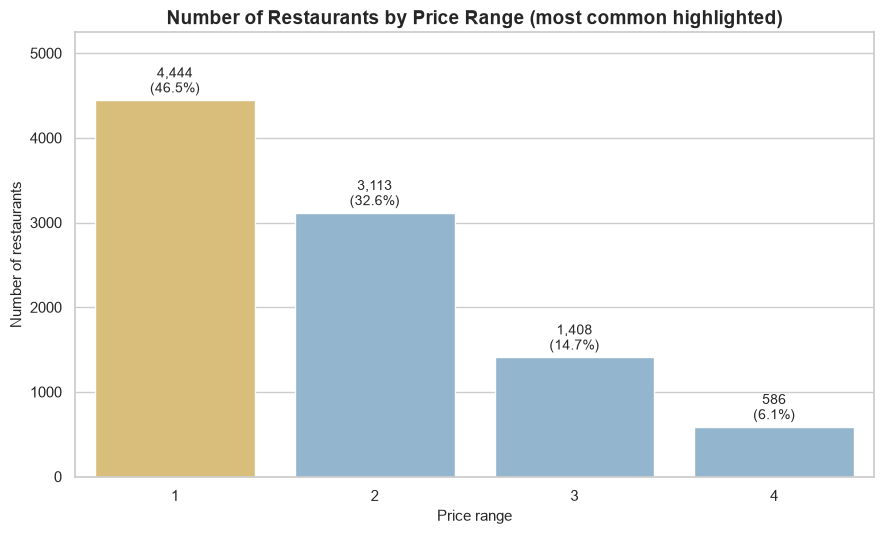

In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))
bar_colors = ["#e9c46a" if idx in most_common_ranges else "#8ab6d6" for idx in count_table.index]
sns.barplot(x=count_table.index.astype(str), y=count_table["Restaurants"], hue=count_table.index.astype(str),
            palette=dict(zip(count_table.index.astype(str), bar_colors)), legend=False, ax=ax)
for position, (_, row) in enumerate(count_table.iterrows()):
    ax.text(position, row["Restaurants"] + count_table["Restaurants"].max() * 0.01,
            f"{row['Restaurants']:,.0f}\n({row['Share of restaurants (%)']:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.set_title("Number of Restaurants by Price Range (most common highlighted)")
ax.set_xlabel("Price range")
ax.set_ylabel("Number of restaurants")
ax.set_ylim(0, count_table["Restaurants"].max() * 1.18)
plt.tight_layout()
plt.show()

### 9.2 Average rating by price range
Bars show the mean rating of **rated** restaurants (highest bar highlighted); diamonds mark the median; the dashed line is the overall mean of rated restaurants. The right-hand panel shows why unrated zeros must be excluded: they lower every average.

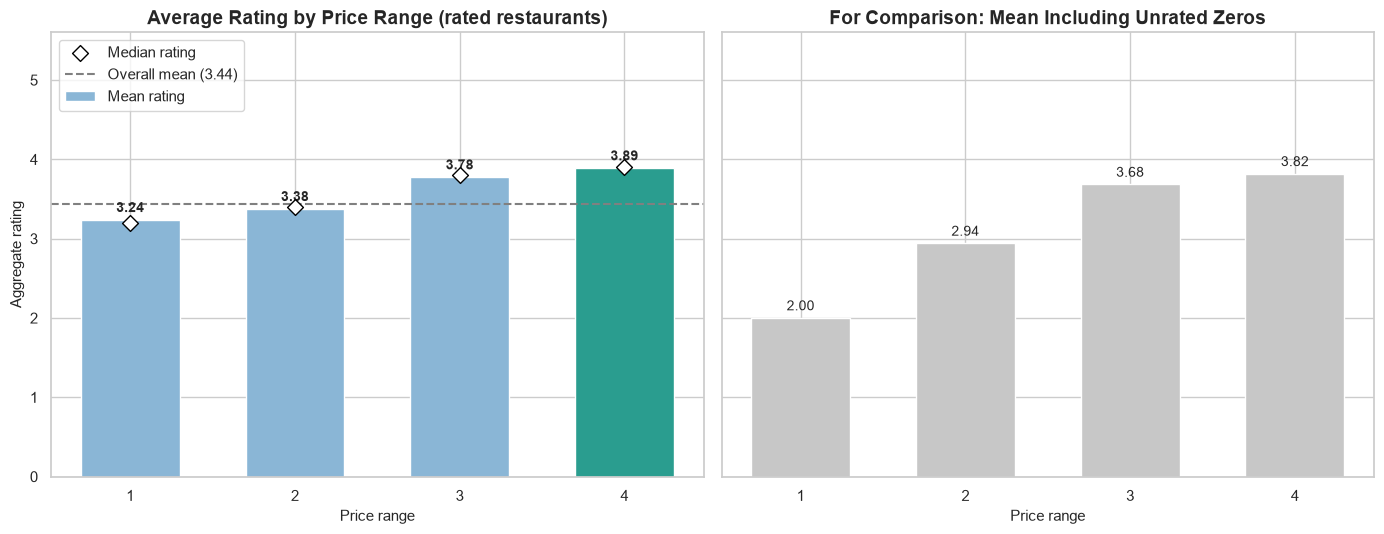

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
labels = summary.index.astype(str)
overall_mean = rated["Aggregate rating"].mean()

ax = axes[0]
colors = ["#2a9d8f" if idx in top_ranges else "#8ab6d6" for idx in summary.index]
ax.bar(labels, summary["Mean Rating"], color=colors, width=0.6, label="Mean rating")
ax.scatter(labels, summary["Median Rating"], marker="D", s=65, color="white", edgecolor="black", zorder=5, label="Median rating")
ax.axhline(overall_mean, color="grey", linestyle="--", label=f"Overall mean ({overall_mean:.2f})")
for position, value in enumerate(summary["Mean Rating"]):
    if pd.notna(value):
        ax.text(position, value + 0.06, f"{value:.2f}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("Average Rating by Price Range (rated restaurants)")
ax.set_xlabel("Price range")
ax.set_ylabel("Aggregate rating")
ax.set_ylim(0, 5.6)
ax.legend(loc="upper left")

ax = axes[1]
ax.bar(labels, summary["Mean incl. unrated zeros"], color="#c7c7c7", width=0.6)
for position, value in enumerate(summary["Mean incl. unrated zeros"]):
    ax.text(position, value + 0.06, f"{value:.2f}", ha="center", va="bottom", fontsize=10)
ax.set_title("For Comparison: Mean Including Unrated Zeros")
ax.set_ylim(0, 5.6)
ax.set_xlabel("Price range")

plt.tight_layout()
plt.show()

### 9.3 Rating colour distribution across price ranges
Every restaurant with a price range is included here (unrated "White" restaurants too), so each bar adds up to 100% of the price range.

**Rating colour distribution within each price range (%)**

,Dark Green,Green,Yellow,Orange,Red,White
Price range,,,,,,
1,0.72,3.24,13.68,42.71,1.40,38.25
2,2.22,10.44,25.51,45.78,3.15,12.91
3,8.95,29.55,35.37,22.23,1.42,2.49
4,12.63,33.11,34.13,17.24,1.02,1.88


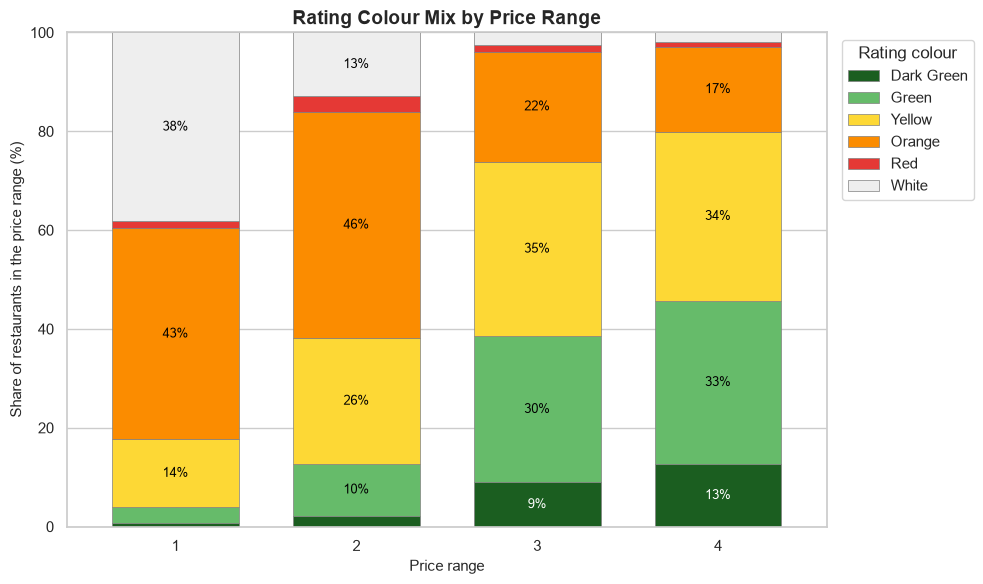

In [12]:
colour_palette = {
    "Dark Green": "#1b5e20", "Green": "#66bb6a", "Yellow": "#fdd835",
    "Orange": "#fb8c00", "Red": "#e53935", "White": "#eeeeee",
}
colour_counts = pd.crosstab(priced["Price range"], priced["Rating color"])
preferred_order = [c for c in colour_palette if c in colour_counts.columns]
other_colours = [c for c in colour_counts.columns if c not in colour_palette]
colour_counts = colour_counts[preferred_order + other_colours]
colour_pct = colour_counts.div(colour_counts.sum(axis=1), axis=0) * 100
colour_pct.columns.name = None

show_table(colour_pct, "Rating colour distribution within each price range (%)")

fig, ax = plt.subplots(figsize=(10, 6))
colour_pct.plot(kind="bar", stacked=True, ax=ax, edgecolor="grey", linewidth=0.5, width=0.7,
                color=[colour_palette.get(c, "#9e9e9e") for c in colour_pct.columns])
for container, column in zip(ax.containers, colour_pct.columns):
    labels = [f"{v:.0f}%" if v >= 5 else "" for v in colour_pct[column]]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=9,
                 color="white" if column in ("Dark Green", "Red") else "black")
ax.set_title("Rating Colour Mix by Price Range")
ax.set_xlabel("Price range")
ax.set_ylabel("Share of restaurants in the price range (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Rating colour", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 10. Key Findings
Generated from the computed results above.

In [13]:
findings = []

if len(most_common_ranges) == 1:
    findings.append(
        f"**Most common price range:** range {most_common} with {price_counts[most_common]:,} restaurants "
        f"({price_share[most_common]:.1f}% of restaurants that have a price range)."
    )
else:
    findings.append(f"**Most common price range:** tie between ranges {most_common_ranges} with {max_count:,} restaurants each.")

least_common = price_counts.idxmin()
findings.append(f"**Least common price range:** range {least_common} with {price_counts[least_common]:,} restaurants ({price_share[least_common]:.1f}%).")

if len(top_ranges) == 1:
    findings.append(f"**Highest average rating:** price range {best_range} with a mean of {highest_mean:.2f} "
                    f"(median {summary.loc[best_range, 'Median Rating']:.2f}, n = {int(summary.loc[best_range, 'Rated Restaurants']):,} rated restaurants).")
else:
    findings.append(f"**Highest average rating:** tie between price ranges {top_ranges} at {highest_mean:.2f}.")

lowest_range = mean_by_range.idxmin()
findings.append(f"**Lowest average rating:** price range {lowest_range} with a mean of {mean_by_range.min():.2f}.")

if mean_by_range.is_monotonic_increasing:
    findings.append("Average rating increases steadily with every step up in price range.")
elif mean_by_range.is_monotonic_decreasing:
    findings.append("Average rating decreases steadily with every step up in price range.")
else:
    findings.append("Average rating does not rise or fall in a single direction across price ranges.")

findings.append(
    f"**Rating colour:** the colour with the highest mean rating is {', '.join(top_colours)} (mean {top_colour_mean:.2f}). "
    f"Price range {best_range}'s average rating falls into the {colour_at_best} band, and its most frequent colour among rated restaurants is {frequent_at_best}."
)
findings.append(
    "Rating colours " + ("overlap in rating value, so colour alone is not a clean measure of rating."
                         if bands_overlap else
                         "occupy separate rating intervals, so the colour is a direct bucket of the rating; "
                         "the highest-rated colour therefore follows from the rating bands rather than being an independent result.")
)
findings.append(
    f"**Data quality:** {len(priced) - len(rated):,} restaurants with a price range are unrated; "
    f"{len(df) - len(priced):,} restaurants have no price range."
)
show_findings(findings)

- **Most common price range:** range 1 with 4,444 restaurants (46.5% of restaurants that have a price range).
- **Least common price range:** range 4 with 586 restaurants (6.1%).
- **Highest average rating:** price range 4 with a mean of 3.89 (median 3.90, n = 575 rated restaurants).
- **Lowest average rating:** price range 1 with a mean of 3.24.
- Average rating increases steadily with every step up in price range.
- **Rating colour:** the colour with the highest mean rating is Dark Green (mean 4.66). Price range 4's average rating falls into the Yellow band, and its most frequent colour among rated restaurants is Yellow.
- Rating colours occupy separate rating intervals, so the colour is a direct bucket of the rating; the highest-rated colour therefore follows from the rating bands rather than being an independent result.
- **Data quality:** 2,148 restaurants with a price range are unrated; 0 restaurants have no price range.

## 11. Conclusion
Written by code from the computed results.

In [14]:
conclusion = [
    f"Price range {most_common} is the most common category ({price_share[most_common]:.1f}% of restaurants).",
    f"Price range {best_range} earns the highest average rating ({highest_mean:.2f}) among rated restaurants, "
    f"while price range {lowest_range} earns the lowest ({mean_by_range.min():.2f}).",
    f"The rating colour linked to the highest average rating is {', '.join(top_colours)}; "
    "because colours map onto rating intervals, this follows from how the colours are assigned rather than being a separate effect of price.",
    "Unrated restaurants (rating 0) were excluded from rating averages; including them would have lowered every price range's average.",
]
show_findings(conclusion)

- Price range 1 is the most common category (46.5% of restaurants).
- Price range 4 earns the highest average rating (3.89) among rated restaurants, while price range 1 earns the lowest (3.24).
- The rating colour linked to the highest average rating is Dark Green; because colours map onto rating intervals, this follows from how the colours are assigned rather than being a separate effect of price.
- Unrated restaurants (rating 0) were excluded from rating averages; including them would have lowered every price range's average.